# Instructions for this notebook:

Prior to running this notebook, the following data must be downloaded and installed in the project folder under Data/Raw/manning/:

[CLRH Hydrofabric dataset](https://hydrology.uwaterloo.ca/CLRH/Hydrofabric.html) (download watershed of interest based on outlet point) 
- Extract zip file to: /Data/Raw/manning/WB_Data/

[NHN streams dataset](https://ftp.maps.canada.ca/pub/nrcan_rncan/vector/geobase_nhn_rhn/shp_en/) (download shapefile corresponding to outlet point ID (e.g., 05OE000)) 
- Extract zip file to: /Data/Raw/manning/WB_Data/

[LiDAR DEM](https://mli.gov.mb.ca/dems/index_external_lidar.html) (download watershed of interest) ***CLIPPED AND RESAMPLED IN ARCGIS PRO
- Extract zip file to: /Data/Raw/manning/WB_Data/

# Calculate Depression Depths (mm) per Subbasin

In [1]:
# Sytem packages
import os
import sys
import fileinput


# Analysis packages
import numpy as np
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point, LineString, Polygon, MultiPoint, mapping
from shapely.geometry import shape as shapely_shape
import rasterio
from rasterio.crs import CRS
from rasterio.mask import mask
from bs4 import BeautifulSoup


# Visualization packages
import matplotlib.pyplot as plt
import rasterio.plot


sys.path.append("..")
from src.py.proj_conf import *

## Process DEM and Stream Network

### Project subbasins shapefile to align with LiDAR raster DEM

In [2]:
# Load CLRH subbasins shapefile
clrh_gdf_file = DATA_RAW + "WB_Data/finalcat_info_v1-0.shp"
clrh_gdf = gpd.read_file(clrh_gdf_file)

In [ ]:
# LiDAR DEM file name with path
input_DEM_file = DATA_RAW + "WB_Data/sr_dem_cgvd28.tif"


# Open LiDAR DEM and check CRS
with rasterio.open(input_DEM_file) as src:
    input_DEM_crs = src.crs


# Project subbasins data to match DEM
clrh_gdf_projected = clrh_gdf.to_crs(input_DEM_crs)


# Remove any non-alphanumeric characters from crs name
input_DEM_crs_alnum = ''.join(c for c in \
                              str(input_DEM_crs) if c.isalnum())


# Projected subbasins shapefile name with path
clrh_gdf_projected_file = DATA_RAW + \
                          f"WB_Data/clrh_basins_projected_{input_DEM_crs_alnum}.shp"


# Write projected subbasins data to shapefile
clrh_gdf_projected.to_file(clrh_gdf_projected_file)


# Check if shapefile projection aligns with DEM projection
is_correctly_projected = (input_DEM_crs == clrh_gdf_projected.crs)
                          

# Print results
print("Shapefile projection is aligned with DEM projection: ", 
      is_correctly_projected)
print(f"Projection is: {input_DEM_crs}")
print("\nIf True and EPSG:26914 are returned, proceed to clipping.")

Shapefile projection is aligned with DEM projection:  True
Projection is: EPSG:26914

If True and EPSG:26914 are returned, proceed to clipping.


c:\Users\iyaktubay\AppData\Local\anaconda3\envs\pwa_dev\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Value 310011982 of field Seg_ID of feature 0 not successfully written. Possibly due to too larger number with respect to field width
  ogr_write(
c:\Users\iyaktubay\AppData\Local\anaconda3\envs\pwa_dev\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Value 310002444 of field Seg_ID of feature 1 not successfully written. Possibly due to too larger number with respect to field width
  ogr_write(
c:\Users\iyaktubay\AppData\Local\anaconda3\envs\pwa_dev\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Value 310002428 of field Seg_ID of feature 2 not successfully written. Possibly due to too larger number with respect to field width
  ogr_write(
c:\Users\iyaktubay\AppData\Local\anaconda3\envs\pwa_dev\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Value 310011981 of field Seg_ID of feature 3 not successfully written. Possibly due to too larger number with respect to f

### Clip LiDAR raster DEM to watershed

In [ ]:
# Convert projected subbasins data to GeoJSON-like format
shapes = [mapping(geom) for geom in clrh_gdf_projected.geometry]


# Mask (clip) the input DEM file
with rasterio.open(input_DEM_file) as src:
    nodata_value = src.nodata
    out_image, out_transform = mask(src, 
                                    shapes, 
                                    crop=True,
                                    all_touched=True                  
                                    )
    out_meta = src.meta.copy()


# Update the copied metadata to match the clipped raster's dimensions and transform
out_meta.update({
    "driver": "GTiff",
    "height": out_image.shape[1],
    "width": out_image.shape[2],
    "transform": out_transform
})


# Clipped DEM file name with path
output_DEM_file = DATA_RAW + "WB_Data/sr_dem_cgvd28_Clip.tif"


# Write clipped DEM data into file
with rasterio.open(output_DEM_file,
                   "w", 
                   **out_meta) as dest:
    dest.write(out_image)


# Print out some stats fyi
valid_out_image = out_image[0][out_image[0] != nodata_value]
print("Clipped unique values:", np.unique(valid_out_image))
print("Clipped number of unique values: ", len(np.unique(valid_out_image)))
print("Clipped maximum value :", np.max(valid_out_image))
print("Clipped minimum value (excluding nodata value): ",  np.min(valid_out_image))
print("\nIf the numbers make sense, proceed to resampling.")


""" #=======================ELENA CODE (WILL DELETE IT SOON)===================================
### SUBBASIN AND STREAM SHAPEFILES WERE PROJECTED IN ARCGIS PRO (NO PROJECTION TOOL IN WHITEBOX)

# Clip NHN streams to study area
# wbt.clip(
#    i = 'NHN_05OE000_5_0_HD_SLWATER_1.shp',
#    clip = 'clrh_basins_projected_4617.shp',
#    output = 'NHN_Clip.shp'
#)

### RASTER DATA WAS CLIPPED AND RESAMPLED IN ARCGIS PRO DUE TO MEMORY ALLOCATION ERROR

# Clip dem raster to study area
#wbt.clip_raster_to_polygon(
    #i = 'sr_dem_cgvd28.tif',
    #polygons = 'finalcat_info_v1-0_Project.shp',
    #output = 'sr_dem_cgvd28_Clip_MC.tif'
#)

# Resample DEM to 5m (for faster processing)
#wbt.resample(
    #inputs = 'sr_dem_cgvd28_Clip_MC.tif',
    #output = 'sr_dem_cgvd28_Clip_MC_Resample_5m_corr',
    #cell_size = 5,
    #method = "cc"
#) """

Clipped unique values: [236.857 236.861 236.863 ... 317.783 317.788 317.872]
Clipped number of unique values:  634741
Clipped maximum value : 317.872
Clipped minimum value (excluding nodata value):  236.857

If the numbers make sense, proceed to resampling.


' #===========================================ELENA CODE========================================================\n### SUBBASIN AND STREAM SHAPEFILES WERE PROJECTED IN ARCGIS PRO (NO PROJECTION TOOL IN WHITEBOX)\n\n# Clip NHN streams to study area\n# wbt.clip(\n#    i = \'NHN_05OE000_5_0_HD_SLWATER_1.shp\',\n#    clip = \'clrh_basins_projected_4617.shp\',\n#    output = \'NHN_Clip.shp\'\n#)\n\n### RASTER DATA WAS CLIPPED AND RESAMPLED IN ARCGIS PRO DUE TO MEMORY ALLOCATION ERROR\n\n# Clip dem raster to study area\n#wbt.clip_raster_to_polygon(\n    #i = \'sr_dem_cgvd28.tif\',\n    #polygons = \'finalcat_info_v1-0_Project.shp\',\n    #output = \'sr_dem_cgvd28_Clip_MC.tif\'\n#)\n\n# Resample DEM to 5m (for faster processing)\n#wbt.resample(\n    #inputs = \'sr_dem_cgvd28_Clip_MC.tif\',\n    #output = \'sr_dem_cgvd28_Clip_MC_Resample_5m_corr\',\n    #cell_size = 5,\n    #method = "cc"\n#) '

### Resample clipped LiDAR raster DEM to 5m resolution

In [ ]:
# Import whitebox
from WBT.whitebox_tools import WhiteboxTools

# Save current working directory
default_directory = os.getcwd()

wbt = WhiteboxTools()

# This line could probably could get cleaned up...
wbt.set_working_dir(os.path.abspath(os.path.join(os.path.dirname("__file__"),  '..', 'Data/Raw/manning/WB_Data')))

In [ ]:
# Define resolution
resolution = 5 
resolution_units = "m" # metres


# Resample to defined resolution
wbt.resample(
    inputs="sr_dem_cgvd28_Clip.tif",
    output=f"sr_dem_cgvd28_Clip_Resample_{resolution}{resolution_units}",
    cell_size = resolution,
    method = "cc"
)


# After using whitebox, jump back into default directory to avoid path errors
os.chdir(default_directory)


# Clipped resampled DEM file name with path
output_DEM_clires_file = DATA_RAW + \
                        f"WB_Data/sr_dem_cgvd28_Clip_Resample_{resolution}{resolution_units}.tif"


# Open the clipped resampled file to get some stats
with rasterio.open(output_DEM_clires_file) as src:
    image = src.read(1)


# Print out some stats fyi
valid_image = np.ma.masked_equal(image, nodata_value)
print("Clipped resampled DEM unique values:", np.unique(valid_image))
print("Clipped resampled number of unique values: ", len(np.unique(valid_image)))
print("Clipped resampled maximum value :", np.max(valid_image))
print("Clipped resampled minimum value (excluding nodata value): ",  np.min(valid_image))
print("\nIf the numbers make sense, proceed to next sections.")


.\whitebox_tools.exe --run="Resample" --wd="c:\Users\iyaktubay\PWA\Data\Raw\manning\WB_Data" --inputs='sr_dem_cgvd28_Clip.tif' --output='sr_dem_cgvd28_Clip_Resample_5m' --cell_size='5' --method=cc -v --compress_rasters=False

****************************
* Welcome to Resample      *
* Powered by WhiteboxTools *
* www.whiteboxgeo.com      *
****************************
Reading data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
Progress: 41%
Progress: 42%
Progress: 43%
Progres

### Visualize clipped and resampled LiDAR raster DEM

c:\Users\iyaktubay\AppData\Local\anaconda3\envs\pwa_dev\Lib\site-packages\matplotlib\colors.py:777: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


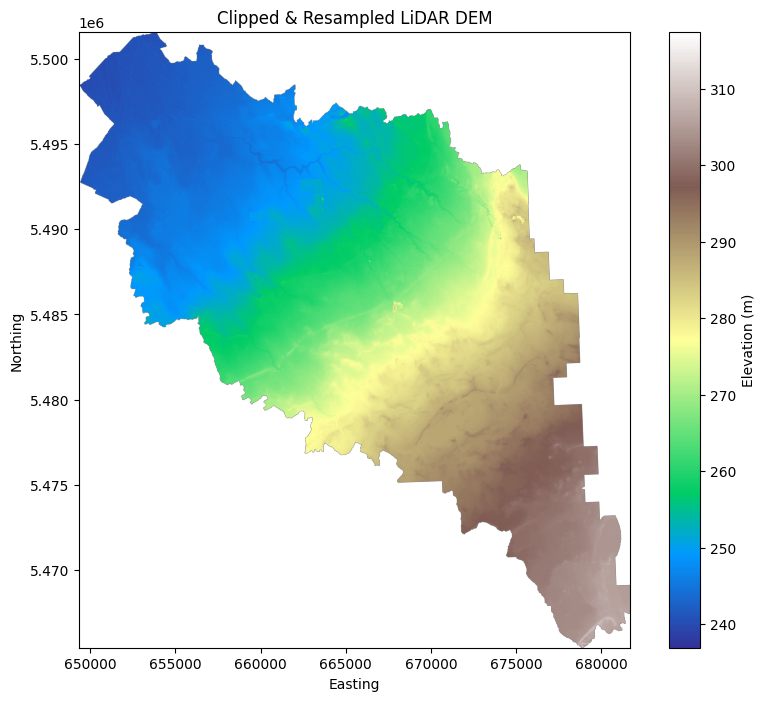

In [7]:
# Open the clipped and resampled file to visualize
with rasterio.open(output_DEM_clires_file) as src:
    image = src.read(1)
    extent = rasterio.plot.plotting_extent(src)


# Visualize clipped and resampled file
valid_image = np.ma.masked_equal(image, nodata_value)
plt.figure(figsize=(10, 8))
plt.imshow(valid_image, cmap='terrain', extent=extent)
plt.colorbar(label='Elevation (m)')
plt.title("Clipped & Resampled LiDAR DEM")
plt.xlabel("Easting")
plt.ylabel("Northing")
plt.show()

### ANYTHING BEYOND THIS POINT IS BROKEN CODE (IY NEEDS TO CLEAN IT UP)

In [26]:
os.getcwd()

### RUNNING WHITEBOX TOOLS CHANGES THE WORKING DIRECTORY (ADDS WBT FOLDER). NOTEBOOK MUST BE RUN TOP TO BOTTOM, OTHERWISE PATHS WITLL NOT WORK

'C:\\Users\\iyaktubay\\PWA'

In [19]:
# Project NHN clipped shapefile
streams_clip = gpd.read_file(os.path.abspath(os.path.join(os.path.dirname("__file__"), '..', '..', 'Data/Raw/manning/WB_Data')) + "/" + "NHN_Clip.shp")
streams_clip_proj_26914 = streams_clip.to_crs(26914)
streams_clip_proj_26914.to_file(os.path.abspath(os.path.join(os.path.dirname("__file__"), '..', '..', 'Data/Raw/manning/WB_Data')) + "/" + "NHN_Clip_Project_26914.shp")

## Generate Depressions Raster

In [20]:
# Burn streams into DEM and fill
wbt.fill_burn(
    dem = 'sr_dem_cgvd28_Clip_MC_Resample_5m_corr.tif',
    streams = 'NHN_Clip_Project_26914.shp',
    output = 'DEM_Clip_MC_Resample_5m_FillBurn.tif'
)

# Subtract raw DEM from filled DEM
wbt.raster_calculator(
    output = 'DEM_Clip_MC_Resample_5m_FillBurn_Deps.tif',
    statement = "'DEM_Clip_MC_Resample_5m_FillBurn.tif' - 'sr_dem_cgvd28_Clip_MC_Resample_5m_corr.tif'"
)

# Remove stray burn lines
wbt.conditional_evaluation(
    i = 'DEM_Clip_MC_Resample_5m_FillBurn_Deps.tif',
    output = 'DEM_Clip_MC_Resample_5m_FillBurn_Deps_Corr.tif',
    statement = "value < 0.0",
    true = 0.0,
    false = 'DEM_Clip_MC_Resample_5m_FillBurn_Deps.tif'
)

.\whitebox_tools.exe --run="FillBurn" --wd="c:\Users\iyaktubay\PWA\Data\Raw\manning\WB_Data" --dem='sr_dem_cgvd28_Clip_MC_Resample_5m_corr.tif' --streams='NHN_Clip_Project_26914.shp' --output='DEM_Clip_MC_Resample_5m_FillBurn.tif' -v --compress_rasters=False

****************************
* Welcome to FillBurn      *
* Powered by WhiteboxTools *
* www.whiteboxgeo.com      *
****************************


Reading streams data...
Reading DEM data...
thread 'main' panicked at whitebox-tools-app\src\main.rs:72:21:
The system cannot find the file specified. (os error 2)
note: run with `RUST_BACKTRACE=1` environment variable to display a backtrace
.\whitebox_tools.exe --run="RasterCalculator" --wd="c:\Users\iyaktubay\PWA\Data\Raw\manning\WB_Data" --statement='DEM_Clip_MC_Resample_5m_FillBurn.tif' - 'sr_dem_cgvd28_Clip_MC_Resample_5m_corr.tif' --output='DEM_Clip_MC_Resample_5m_FillBurn_Deps.tif' -v --compress_rasters=False

*******************************
* Welcome to RasterCalculator *
* Powered by WhiteboxTools    *
* www.whiteboxgeo.com         *
*******************************
Reading data...
thread 'main' panicked at whitebox-plugins\src/raster_calculator/main.rs:137:23:
Os { code: 2, kind: NotFound, message: "The system cannot find the file specified." }
note: run with `RUST_BACKTRACE=1` environment variable to display a backtrace
Failure to run plugin subprocess.
.\whitebox_tools.exe -

0

## Calculate Depression Depths per Subbasin

In [21]:
# Convert clrh subbasin polygons to raster
wbt.vector_polygons_to_raster(
    i = 'clrh_basins_projected_26914.shp',
    output = 'clrh_basins_raster.tif',
    field = "FID",
    nodata = True,
    cell_size = 5.0
)

# Define projection of clrh raster
with rasterio.open(os.path.abspath(os.path.join(os.path.dirname("__file__"), '..', '..', 'Data/Raw/manning/WB_Data')) + "/" + 'clrh_basins_raster.tif', 'r+') as rds:
    rds.crs = CRS.from_epsg(26914)

# Calculate zonal statistics
wbt.zonal_statistics(
    i = 'DEM_Clip_MC_Resample_5m_FillBurn_Deps_Corr.tif',
    features = 'clrh_basins_raster.tif',
    stat="total",
    out_table='ZonalStats_DEM_Clip_MC_Resample_5m_FillBurn_Deps_Corr.html'
)

.\whitebox_tools.exe --run="VectorPolygonsToRaster" --wd="c:\Users\iyaktubay\PWA\Data\Raw\manning\WB_Data" --input='clrh_basins_projected_26914.shp' --field=FID --output='clrh_basins_raster.tif' --nodata --cell_size='5.0' -v --compress_rasters=False

*************************************
* Welcome to VectorPolygonsToRaster *
* Powered by WhiteboxTools          *
* www.whiteboxgeo.com               *
*************************************


Reading data...
Reading attributes: 0%
Reading attributes: 1%
Reading attributes: 3%
Reading attributes: 5%
Reading attributes: 6%
Reading attributes: 8%
Reading attributes: 10%
Reading attributes: 11%
Reading attributes: 13%
Reading attributes: 15%
Reading attributes: 16%
Reading attributes: 18%
Reading attributes: 20%
Reading attributes: 21%
Reading attributes: 23%
Reading attributes: 25%
Reading attributes: 26%
Reading attributes: 28%
Reading attributes: 30%
Reading attributes: 31%
Reading attributes: 33%
Reading attributes: 35%
Reading attributes: 36%
Reading attributes: 38%
Reading attributes: 40%
Reading attributes: 41%
Reading attributes: 43%
Reading attributes: 45%
Reading attributes: 46%
Reading attributes: 48%
Reading attributes: 50%
Reading attributes: 51%
Reading attributes: 53%
Reading attributes: 55%
Reading attributes: 56%
Reading attributes: 58%
Reading attributes: 60%
Reading attributes: 61%
Reading attributes: 63%
Reading attributes: 65%
Reading attributes: 66%
Readin

0

In [13]:
# Read html file as pandas dataframe
file = os.path.abspath(os.path.join(os.path.dirname("__file__"), '..', '..', 'Data/Raw/manning/WB_Data')) + "/" + 'ZonalStats_DEM_Clip_MC_Resample_5m_FillBurn_Deps_Corr.html'
zonal_stats_dfs = pd.read_html(file, flavor='bs4')
zonal_stats_df = zonal_stats_dfs[0]

# Join totals to clrh subbasins geodataframe
clrh_gdf_projected_26914['Deps_SUM'] = zonal_stats_df['Total']

# Calculate depression volumes (m3) and add field to gdf
clrh_gdf_projected_26914['Deps_Vol_m3'] = clrh_gdf_projected_26914['Deps_SUM'] * 5 * 5

# Calculate depression depths (mm) and add field to gdf
clrh_gdf_projected_26914['Deps_Depth_mm'] = clrh_gdf_projected_26914['Deps_Vol_m3'] / clrh_gdf_projected_26914['BasArea'] * 1000

In [16]:
# Write geodataframe to file for use in raven input file creation
clrh_gdf_projected_26914.to_file(os.path.abspath(os.path.join(os.path.dirname("__file__"), '..', '..', 'Data/Raw/manning/WB_Data')) + "/" + "clrh_basins_deps.shp")


C:\Users\emilito\AppData\Local\Temp\ipykernel_39120\1600728456.py:2: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  clrh_gdf_projected_26914.to_file(os.path.abspath(os.path.join(os.path.dirname("__file__"), '..', '..', 'Data/Raw/manning/WB_Data')) + "/" + "clrh_basins_deps.shp")
c:\Users\emilito\AppData\Local\anaconda3\envs\pwa_dev\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'Deps_Vol_m3' to 'Deps_Vol_m'
  ogr_write(
c:\Users\emilito\AppData\Local\anaconda3\envs\pwa_dev\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'Deps_Depth_mm' to 'Deps_Depth'
  ogr_write(
c:\Users\emilito\AppData\Local\anaconda3\envs\pwa_dev\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Value 310011982 of field Seg_ID of feature 0 not successfully written. Possibly due to too larger number with respect to field width
  ogr_write(
c:\Users\emilito\AppData\Local\anaconda3\